**Logistic Regression + T3: PCA(15) ---> Polynomial degree 3**

This notebook trains **LR with transformation T3** for 6 values of `C` (6 of our 72 models). It uses the shared splits (`data/processed/`), preprocessing (`src/preprocessing.py`) and evaluation (`src/evaluation.py`), so the results can be merged with the other notebooks. We only use train and validation here; the test set is used once at the end of the project.

**Logistic regression** predicts the probability of an attack as $P(\text{attack}) = \sigma(w^\top x + b)$, where $\sigma(z) = 1 / (1 + e^{-z})$ squashes any number into (0, 1). It flags a flow as an attack when that probability is above 0.5, so the decision boundary $w^\top x + b = 0$ is a straight line (hyperplane) in the feature space it sees.

**Regularization:** sklearn minimizes

$$\frac{1}{2}\lVert w \rVert^2 + C \sum_{i} \text{log-loss}_i$$

`C` sets how much the model cares about fitting the training data compared to keeping the weights small. **Small `C` ---> strong regularization** (small weights, simpler model, risk of underfitting). **Large `C` ---> weak regularization** (fits training data closely, risk of overfitting). `C` plays the role of $1/\lambda$.

**1. Setup**

In [1]:
import sys
sys.path.append("..") # so we can import from src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.decomposition import PCA
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LogisticRegression

from src.preprocessing import RANDOM_STATE, build_preprocessor, load_split
from src.evaluation import evaluate, plot_sweep, attack_recall, RESULTS

FIGS = RESULTS.parent / "figures"
RESULTS.mkdir(exist_ok=True)

X_train, y_train, cat_train = load_split("train")
X_val, y_val, cat_val = load_split("val")
print("train:", X_train.shape, " val:", X_val.shape)

train: (24000, 41)  val: (6000, 41)


**2. The transformation: PCA(15) ---> polynomial degree 3**

A linear model can only draw a straight boundary. Polynomial features add squares, cubes and products of features, so the model stays linear in the new features but draws a **curved** boundary in the original space. For example, the product of two features captures "both are high at the same time" (many packets *and* a very short duration).

Degree 3 on all 73 features would give $\binom{76}{3} - 1 = 70{,}299$ columns, which is too many for 24,000 rows. So we first compress to 15 components with PCA, then expand:

$$\binom{15 + 3}{3} - 1 = 815 \text{ columns}$$

We add a `StandardScaler` after the polynomial step, since cubes of components have very different scales and logistic regression converges badly without it.

**Why do we do this?**: Compress first, then add curvature ---> nonlinear boundaries at a manageable size

In [2]:
prep = build_preprocessor().fit(X_train)
Xt_train = prep.transform(X_train)
pca15 = PCA(n_components=15, random_state=RANDOM_STATE).fit(Xt_train)
poly = PolynomialFeatures(degree=3, include_bias=False).fit(pca15.transform(Xt_train))

print(f"PCA(15) keeps {pca15.explained_variance_ratio_.sum():.1%} of the variance")
print("columns: 73 ---> 15 ---> ", poly.n_output_features_)

PCA(15) keeps 93.5% of the variance
columns: 73 ---> 15 --->  815


How the 815 columns break down by degree (`x0` is the first principal component, `x0 x1` a product of two components, `x0^3` a cube):

In [3]:
poly_names = poly.get_feature_names_out()
degree = poly.powers_.sum(axis=1) # degree of each new column
for d in [1, 2, 3]:
    print(f"degree {d}: {(degree == d).sum():>3} columns, e.g. {list(poly_names[degree == d][:3])}")

degree 1:  15 columns, e.g. ['x0', 'x1', 'x2']
degree 2: 120 columns, e.g. ['x0^2', 'x0 x1', 'x0 x2']
degree 3: 680 columns, e.g. ['x0^3', 'x0^2 x1', 'x0^2 x2']


PCA(15) keeps **93.5% of the variance**, a bit less than the 95% (17 components) used in T2, so we start from a slightly more compressed version of the data. The polynomial step then expands the 15 components to **815 columns**: 15 of degree 1, 120 of degree 2 and 680 of degree 3. So 83% of the new columns are cubic terms.

The products are what make this transformation interesting. For example, a term like `x0 x1` multiplies PC1 (back-and-forth TCP conversation vs fast one-shot flow) with PC2 (the TTL / little-reply "attack direction"), which lets the model react to "one-shot flow **and** attack-like TTL" together instead of adding the two effects separately. This is something T0 and T2 cannot express, since their boundary is a straight line.

**Why does this matter?**: Going from 17 columns (T2) to 815 is a big jump in model capacity, with only about 29 training rows per column ---> we expect higher training scores, and the regularization `C` should matter much more here than in T2.

**3. The pipeline**

The full pipeline: shared preprocessing (73 features) ---> PCA(15) ---> polynomial degree 3 (815 columns) ---> scaling ---> logistic regression.

In [4]:
def build(C):
    return make_pipeline(build_preprocessor(),
                         PCA(n_components=15, random_state=RANDOM_STATE),
                         PolynomialFeatures(degree=3, include_bias=False),
                         StandardScaler(),
                         LogisticRegression(C=C, max_iter=2000))

**4. Regularization sweep**

We train one model for each of the 6 values of `C` (smaller `C` = stronger regularization). Every model is fit on the 24,000 training rows and scored on both train and validation. `f1_gap` = train F1 - validation F1: a big gap means overfitting, while low F1 on both means underfitting.

In [5]:
GRID = [1e-3, 1e-2, 1e-1, 1, 10, 100]
rows, fitted = [], {} # fitted keeps each trained pipeline, so we don't have to retrain the best one

for value in GRID:
    pipe = build(value)
    rows.append(evaluate(pipe, "LR", "T3", "C", value, X_train, y_train, X_val, y_val))
    fitted[value] = pipe
    print(f"C={value:g}: val F1 = {rows[-1]['val_f1']:.4f}, fit time = {rows[-1]['fit_time_s']}s")

results = pd.DataFrame(rows)
results["f1_gap"] = results["train_f1"] - results["val_f1"]
results.drop(columns=["model", "transformation", "param"]).round(4)

C=0.001: val F1 = 0.9074, fit time = 0.48s
C=0.01: val F1 = 0.9115, fit time = 0.6s
C=0.1: val F1 = 0.9163, fit time = 1.16s
C=1: val F1 = 0.9179, fit time = 2.04s
C=10: val F1 = 0.9163, fit time = 3.86s
C=100: val F1 = 0.9164, fit time = 6.29s


,value,train_precision,train_recall,train_f1,train_fpr,val_precision,val_recall,val_f1,val_fpr,fit_time_s,converged,f1_gap
0,0.001,0.8676,0.9569,0.9101,0.1572,0.8684,0.9502,0.9074,0.1550,0.48,True,0.0026
1,0.010,0.8792,0.9617,0.9186,0.1422,0.8742,0.9521,0.9115,0.1474,0.60,True,0.0071
2,0.100,0.8941,0.9580,0.9250,0.1222,0.8862,0.9486,0.9163,0.1311,1.16,True,0.0087
3,1.000,0.9041,0.9515,0.9272,0.1087,0.8971,0.9395,0.9179,0.1159,2.04,True,0.0093
4,10.000,0.9120,0.9467,0.9290,0.0983,0.9034,0.9296,0.9163,0.1069,3.86,True,0.0127
5,100.000,0.9176,0.9480,0.9326,0.0916,0.9042,0.9289,0.9164,0.1059,6.29,True,0.0161


**5. Validation curve**

Left: train F1 (dashed) vs validation F1 (solid). Right: validation precision, recall and false positive rate, to see what the regularization trades off.

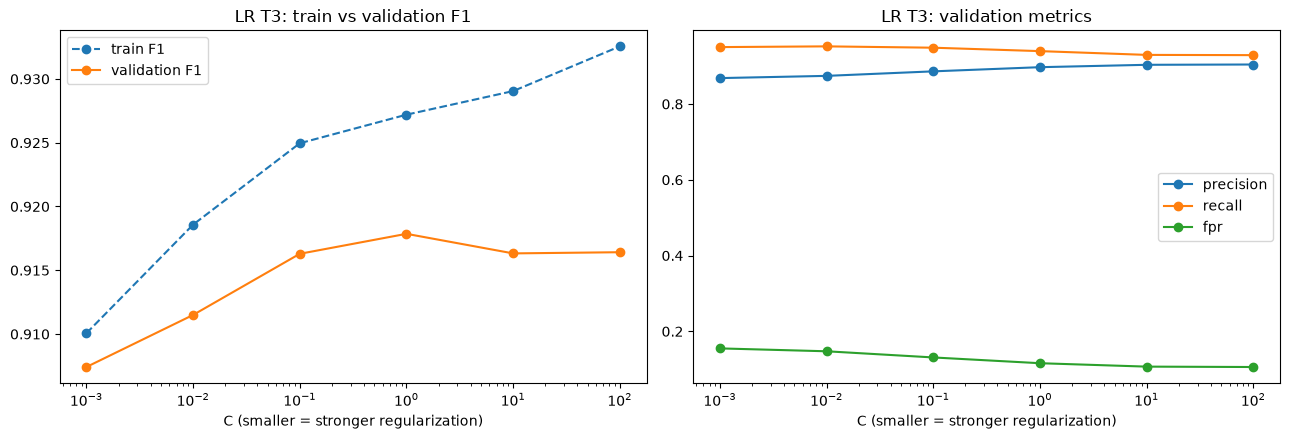

In [6]:
plot_sweep(results, "LR T3", FIGS / "curve_lr_t3_pca_poly3.png")

With 815 columns, weaker regularization (larger `C`) lets the model use more of them, which costs training time. We check how the fit time and the gap between train and validation F1 grow with `C`.

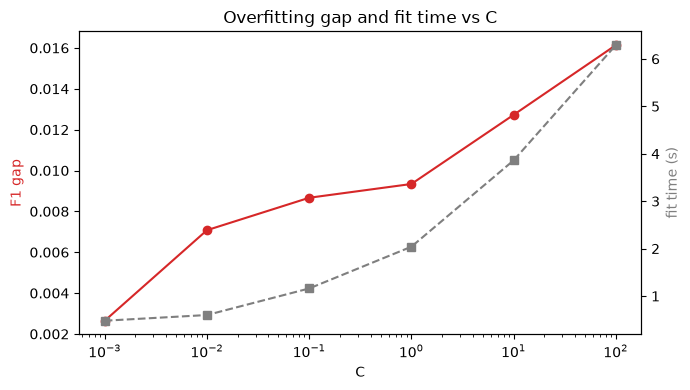

In [7]:
fig, ax1 = plt.subplots(figsize=(7, 4))
ax1.plot(results["value"], results["f1_gap"], "-o", color="tab:red", label="train F1 - val F1")
ax1.set_xscale("log")
ax1.set_xlabel("C")
ax1.set_ylabel("F1 gap", color="tab:red")
ax2 = ax1.twinx()
ax2.plot(results["value"], results["fit_time_s"], "--s", color="tab:gray")
ax2.set_ylabel("fit time (s)", color="tab:gray")
plt.title("Overfitting gap and fit time vs C")
plt.tight_layout()
plt.show()

Validation F1 rises from 0.9074 at `C` = 0.001 to its **peak of 0.9179 at `C` = 1**, then drops slightly to about 0.916 for `C` = 10 and 100. Unlike T2, the best value is in the middle of the grid, so we don't need to extend it.

This is the clearest **overfitting** pattern so far: training F1 keeps going up the whole way (0.9101 ---> 0.9326), while validation F1 stops improving after `C` = 1. The gap between them grows six times, from 0.0026 to 0.0161. Weaker regularization lets the model use more of the 815 columns to fit the training data, but past `C` = 1 those extra details don't carry over to new flows. Fit time also grows from 0.48s to 6.29s, so weak regularization is both slower and worse.

Precision, recall and FPR move in opposite directions as `C` grows:
- Precision goes up from 0.868 to 0.904 and FPR drops from 0.155 to 0.106
- Recall goes down from 0.950 to 0.929

Compared with T2 (best val F1 0.8999, FPR 0.150), T3 is clearly better: +0.018 F1 and 3.4 percentage points fewer false alarms. It also slightly beats T0 (0.914), so adding the polynomial terms after PCA more than makes up for the information PCA throws away.

**Why does this matter?**: This is the expected bias-variance trade-off ---> T2 was underfitting, T3 has enough capacity to start overfitting, and `C` = 1 is the balance point between the two.

**6. The best setting**

We pick the `C` with the highest validation F1. If it is at the edge of the grid, the best value might be outside it, and we should consider extending the grid.

In [8]:
best = results.loc[results["val_f1"].idxmax()]
best_model = fitted[best["value"]]
print(f"best C = {best['value']:g}: val F1 = {best['val_f1']:.4f}, precision = {best['val_precision']:.4f}, "
      f"recall = {best['val_recall']:.4f}, FPR = {best['val_fpr']:.4f}")
if best["value"] in (GRID[0], GRID[-1]):
    print("the best value is at the edge of the grid ---> consider extending it")

best C = 1: val F1 = 0.9179, precision = 0.8971, recall = 0.9395, FPR = 0.1159


The confusion matrix on the validation set: the top-right cell is false alarms (normal flagged as attack), the bottom-left cell is missed attacks.

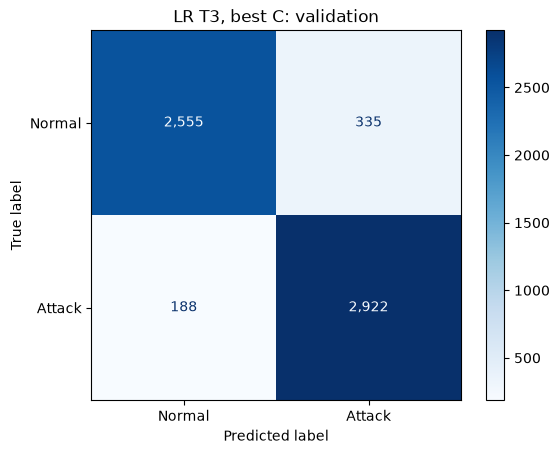

In [9]:
pred_val = best_model.predict(X_val)
ConfusionMatrixDisplay.from_predictions(y_val, pred_val, display_labels=["Normal", "Attack"], cmap="Blues", values_format=",")
plt.title("LR T3, best C: validation")
plt.savefig(FIGS / "confusion_lr_t3_pca_poly3.png", dpi=150, bbox_inches="tight")
plt.show()

Which attack types does the best model miss? (On validation only, the test set stays untouched.)

In [10]:
attack_recall(y_val, pred_val, cat_val)

,rows,caught,missed,recall
type,,,,
Fuzzers,899,745,154,0.829
Analysis,89,81,8,0.910
Exploits,1105,1087,18,0.984
Generic,233,230,3,0.987
Backdoor,85,84,1,0.988
Reconnaissance,419,416,3,0.993
DoS,212,211,1,0.995
Shellcode,61,61,0,1.000
Worms,7,7,0,1.000


The best model (`C` = 1) makes 335 false alarms (11.6% of normal flows) and misses 188 attacks (6.0%), compared with 434 and 211 for LR T2. So the extra flexibility mainly reduces false alarms.

The improvement comes from almost every attack type **except Fuzzers**:
- Exploits: 39 ---> 18 missed, DoS: 7 ---> 1, Backdoor: 6 ---> 1, Reconnaissance: 8 ---> 3, Generic: 6 ---> 3
- **Fuzzers got slightly worse**: 154 missed (recall 82.9%) vs 141 in T2, and they are now 82% of all missed attacks
- Analysis also went from 4 to 8 missed, but with only 89 rows that is a small change

So the curved boundary helps with attacks that have a distinctive flow pattern, but not with Fuzzers. This matches the EDA: Fuzzers send malformed data, but at the flow level they look like normal traffic, so a more flexible boundary on the same features cannot separate them.

**Why does this matter?**: More model complexity is not the fix for Fuzzers ---> the limit is in what the flow features capture, not in the model. This is a good point for the write-up, and we should check whether the MLPs show the same pattern.

**7. Save the results**

We save the 6 rows to `results/lr_t3_pca_poly3.csv`, so they can be merged with the other notebooks into the 72-row results table.

In [11]:
results.to_csv(RESULTS / "lr_t3_pca_poly3.csv", index=False)
print("saved", len(results), "rows to", RESULTS / "lr_t3_pca_poly3.csv")

saved 6 rows to /Users/nerominh/Documents/Fall 2026/Machine Learning/Network Fraud Detection/results/lr_t3_pca_poly3.csv
